# 06 — Pipeline: Inference Strategies, Ensembling & Temporal Post-Processing

Each step is measured separately on val.

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Data-strategy gains

In [2]:
data_gains = pd.DataFrame([
    ("ignore policy blur -> drop (YOLO11n, k=10)", "yolo-u12_blur", "yolo-u12_drop"),
    ("k=5 -> k=2 frames, fine-tune + copy-paste (RT-DETR-L)", "rtdetr-e0", "rtdetr-e3-ft"),
], columns=["change", "from", "to"])
for i, r in data_gains.iterrows():
    a, b = run_summary(r["from"]), run_summary(r["to"])
    data_gains.loc[i, "AP from"], data_gains.loc[i, "AP to"] = a["AP"], b["AP"]
    data_gains.loc[i, "APs from"], data_gains.loc[i, "APs to"] = a["APs"], b["APs"]
data_gains["ΔAP"] = data_gains["AP to"] - data_gains["AP from"]
display(data_gains.round(4))

,change,from,to,AP from,AP to,APs from,APs to,ΔAP
0,"ignore policy blur -> drop (YOLO11n, k=10)",yolo-u12_blur,yolo-u12_drop,0.1873,0.1912,0.0952,0.0890,0.0039
1,"k=5 -> k=2 frames, fine-tune + copy-paste (RT-...",rtdetr-e0,rtdetr-e3-ft,0.2654,0.2596,0.1370,0.1264,-0.0058


**Notes.** `drop` > `blur` (+0.004 AP). Fine-tuning on `k=2` lowered RT-DETR AP (−0.006); the model is still used in the v2 ensemble.

## 2. Inference strategies

Tiling: 960×960 windows, 25% overlap, merged with the full frame by WBF. TTA: scales {1.0, 1.15} + horizontal flip.

In [3]:
from vdet.data.manifest import load_manifest
from vdet.pipeline import ensure_split_predictions

INFERENCE_VARIANTS = [
    dict(run_id="yolo-e1-tiled", base_run_id="yolo-e1", weights="checkpoints/yolo-e1_best.pt", imgsz=1280, batch=4,
         tiling=True, slice_size=960, overlap=0.25, upscale_small_frames=True, wbf_weight=1.8),
    dict(run_id="rtdetr-e3-tta", base_run_id="rtdetr-e3-ft", weights="checkpoints/rtdetr-e3-ft_best.pt", imgsz=1280, batch=2,
         tta=True, tta_scales=[1.0, 1.15], tta_hflip=True, hflip_only_at_base_scale=True, wbf_weight=3.5),
    dict(run_id="yolo11m-e3-tta", base_run_id="yolo11m-e3", weights="checkpoints/yolo11m-e3_best.pt", imgsz=1600, batch=2,
         tta=True, tta_scales=[1.0, 1.15], tta_hflip=True, hflip_only_at_base_scale=True, wbf_weight=2.5),
]
manifest_df = load_manifest()
rows = []
for spec in INFERENCE_VARIANTS:
    p = ensure_split_predictions(spec, "val", manifest_df)   # runs the TTA / tiled inference if not done yet
    base = evaluate_preds(P.runs / spec["base_run_id"] / "preds_val.parquet")
    var = evaluate_preds(p)
    rows.append({"strategy": spec["run_id"], "base": spec["base_run_id"],
                 "AP base": base["AP"], "AP strategy": var["AP"], "ΔAP": var["AP"] - base["AP"],
                 "APs base": base["APs"], "APs strategy": var["APs"], "AR500 base": base["AR500"], "AR500 strategy": var["AR500"]})
inference_gains = pd.DataFrame(rows).round(4)
display(inference_gains)

,strategy,base,AP base,AP strategy,ΔAP,APs base,APs strategy,AR500 base,AR500 strategy
0,yolo-e1-tiled,yolo-e1,0.2184,0.2179,-0.0005,0.1312,0.1553,0.3716,0.3941
1,rtdetr-e3-tta,rtdetr-e3-ft,0.2596,0.2618,0.0022,0.1264,0.1300,0.4200,0.4283
2,yolo11m-e3-tta,yolo11m-e3,0.2118,0.2211,0.0093,0.1393,0.1459,0.3704,0.3952


**Notes.** TTA: +0.009 AP (YOLO11m), +0.002 (RT-DETR). Tiling: AP unchanged, AP_small 0.131 → 0.155, AR500 0.372 → 0.394.

## 3. Pipeline v1 (`pipeline-final`): 6-model WBF + temporal post-processing

Temporal: per class, link boxes across frames (IoU / velocity ≥ 0.45) → `s' = 0.7·s + 0.3·ref(tracklet)` → fill gaps ≤ 2 frames (score ×0.85) → optional 3-frame box smoothing. Steps after linking also use future frames (offline).

In [4]:
from vdet.pipeline import run_pipeline

TEMPORAL = dict(method="rescore", iou_link=0.45, alpha=0.70, topk_ratio=0.50, enable_propagation=True,
                prop_min_score=0.25, prop_min_len=3, max_gap=2, gap_decay=0.85, single_frame_decay=0.96)
FUSION = dict(method="wbf", iou_thr=0.55, skip_box_thr=0.001, conf_type="avg", max_det=500)

PIPELINE_FINAL = dict(
    run_id="pipeline-final", family="pipeline", exp="final", parent_run="rtdetr-e0", seed=42,
    hypothesis="Cross-family Weighted Box Fusion (YOLO11s @1600/1280 + RT-DETR-L nq=300/600) followed by temporal tracklet rescoring and linear gap propagation yields cumulative holdout AP gains over every single model.",
    models=[
        dict(run_id="yolo-e0",   weights="checkpoints/yolo-e0_best.pt",   imgsz=1280, batch=4, wbf_weight=1.0),
        dict(run_id="yolo-e1",   weights="checkpoints/yolo-e1_best.pt",   imgsz=1600, batch=2, wbf_weight=1.5),
        dict(run_id="yolo-e2",   weights="checkpoints/yolo-e2_best.pt",   imgsz=1280, batch=4, wbf_weight=0.8),
        dict(run_id="rtdetr-e0", weights="checkpoints/rtdetr-e0_best.pt", imgsz=1280, batch=2, wbf_weight=2.5),
        dict(run_id="rtdetr-e1", weights="checkpoints/rtdetr-e1_best.pt", imgsz=1280, batch=2, wbf_weight=2.2),
        dict(run_id="rtdetr-e2", weights="checkpoints/rtdetr-e2_best.pt", imgsz=1280, batch=2, wbf_weight=1.8),
    ],
    fusion=dict(FUSION, auto_select_class_wbf=False),
    temporal=TEMPORAL,
)
res_final = run_pipeline(PIPELINE_FINAL, predict_test=True, force_recompute=False)
print("Active models:", res_final["active_models"])

[pipeline] Active ensemble models (6): ['yolo-e0', 'yolo-e1', 'yolo-e2', 'rtdetr-e0', 'rtdetr-e1', 'rtdetr-e2'] with weights [1.0, 1.5, 0.8, 2.5, 2.2, 1.8]
[pipeline] Validation stages (ensemble-wbf, temporal-rescore, pipeline-final) already completed; reusing results.


[pipeline] Reusing existing WBF test predictions from /home/marko/ucu-ai-hw-2/runs/pipeline-final/preds_test_wbf.parquet


[submission] Saved & validated /home/marko/ucu-ai-hw-2/submissions/ensemble_wbf.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1891183, 'mean_dets_per_frame': 496.24}
[pipeline] Reusing existing final test predictions from /home/marko/ucu-ai-hw-2/runs/pipeline-final/preds_test_final.parquet


[submission] Saved & validated /home/marko/ucu-ai-hw-2/submissions/pipeline_final.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1891002, 'mean_dets_per_frame': 496.2}
Active models: ['yolo-e0', 'yolo-e1', 'yolo-e2', 'rtdetr-e0', 'rtdetr-e1', 'rtdetr-e2']


## 4. Pipeline v2 (`pipeline-night-boost`): 12 inputs incl. TTA / tiled variants, class-aware WBF (kept only if better), box smoothing

In [5]:
NIGHT_BOOST = dict(
    run_id="pipeline-night-boost", wbf_run_id="ensemble-wbf-boost", rescore_run_id="temporal-rescore-boost",
    wbf_sub_name="ensemble_wbf_boost.csv", final_sub_name="pipeline_night_boost.csv",
    family="pipeline", exp="night_boost", parent_run="rtdetr-e3-ft", seed=42,
    hypothesis="Combining fine-tuned RT-DETR-L (k=2), YOLO11m@1600, and YOLO11s-P2 with multi-scale/flip TTA, SAHI native-resolution tiling, class-aware WBF, and velocity-projected tracklet rescoring pushes AP significantly beyond 0.30.",
    models=[
        dict(run_id="rtdetr-e3-ft", weights="checkpoints/rtdetr-e3-ft_best.pt", imgsz=1280, batch=2, wbf_weight=3.2),
        INFERENCE_VARIANTS[1],                                     # rtdetr-e3-tta (weight 3.5)
        dict(run_id="yolo11m-e3", weights="checkpoints/yolo11m-e3_best.pt", imgsz=1600, batch=2, wbf_weight=2.2),
        INFERENCE_VARIANTS[2],                                     # yolo11m-e3-tta (weight 2.5)
        dict(run_id="yolo11s-p2", weights="checkpoints/yolo11s-p2_best.pt", imgsz=1280, batch=2, wbf_weight=1.8),
        INFERENCE_VARIANTS[0],                                     # yolo-e1-tiled (weight 1.8)
        dict(run_id="rtdetr-e0", weights="checkpoints/rtdetr-e0_best.pt", imgsz=1280, batch=2, wbf_weight=2.5),
        dict(run_id="rtdetr-e1", weights="checkpoints/rtdetr-e1_best.pt", imgsz=1280, batch=2, wbf_weight=2.2),
        dict(run_id="rtdetr-e2", weights="checkpoints/rtdetr-e2_best.pt", imgsz=1280, batch=2, wbf_weight=1.8),
        dict(run_id="yolo-e1",   weights="checkpoints/yolo-e1_best.pt",   imgsz=1600, batch=2, wbf_weight=1.5),
        dict(run_id="yolo-e0",   weights="checkpoints/yolo-e0_best.pt",   imgsz=1280, batch=4, wbf_weight=1.0),
        dict(run_id="yolo-e2",   weights="checkpoints/yolo-e2_best.pt",   imgsz=1280, batch=4, wbf_weight=0.8),
    ],
    fusion=dict(FUSION, auto_select_class_wbf=True),
    temporal=dict(TEMPORAL, use_velocity=True, small_box_bonus=0.0, smooth_boxes=True, box_smooth_weight=0.16),
)
res_boost = run_pipeline(NIGHT_BOOST, predict_test=True, force_recompute=False)
print("Active models:", res_boost["active_models"])
print("Selected options:", {k: res_boost[k] for k in ("use_class_wbf", "use_smooth_boxes")})

[pipeline] Active ensemble models (12): ['rtdetr-e3-ft', 'rtdetr-e3-tta', 'yolo11m-e3', 'yolo11m-e3-tta', 'yolo11s-p2', 'yolo-e1-tiled', 'rtdetr-e0', 'rtdetr-e1', 'rtdetr-e2', 'yolo-e1', 'yolo-e0', 'yolo-e2'] with weights [3.2, 3.5, 2.2, 2.5, 1.8, 1.8, 2.5, 2.2, 1.8, 1.5, 1.0, 0.8]
[pipeline] Validation stages (ensemble-wbf-boost, temporal-rescore-boost, pipeline-night-boost) already completed; reusing results.


[pipeline] Reusing existing WBF test predictions from /home/marko/ucu-ai-hw-2/runs/pipeline-night-boost/preds_test_wbf.parquet


[submission] Saved & validated /home/marko/ucu-ai-hw-2/submissions/ensemble_wbf_boost.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}
[pipeline] Reusing existing final test predictions from /home/marko/ucu-ai-hw-2/runs/pipeline-night-boost/preds_test_final.parquet


[submission] Saved & validated /home/marko/ucu-ai-hw-2/submissions/pipeline_night_boost.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}
Active models: ['rtdetr-e3-ft', 'rtdetr-e3-tta', 'yolo11m-e3', 'yolo11m-e3-tta', 'yolo11s-p2', 'yolo-e1-tiled', 'rtdetr-e0', 'rtdetr-e1', 'rtdetr-e2', 'yolo-e1', 'yolo-e0', 'yolo-e2']
Selected options: {'use_class_wbf': False, 'use_smooth_boxes': True}


## 4b. Pipeline v3 (`pipeline-v3`): v2 + the three Faster R-CNN models (different model family), same fusion and temporal settings

Added after notebook 03: on val, adding `frcnn-e0/e1/e2` (weight 1.5 each) raised the ensemble AP from 0.3046 to 0.3101. Their test predictions are computed here in separate processes.

In [6]:
from vdet.utils import load_yaml

FRCNN_V3 = []
for rid in ["frcnn-e0", "frcnn-e1", "frcnn-e2"]:
    tv_cfg = load_yaml(P.exp_runs_dir / rid / "config.yaml")           # training config of the run (needed to rebuild the model)
    test_submission(rid, weights=P.ckpt / f"{rid}_best.pth", imgsz=1280, batch=2, tv_config=tv_cfg)   # test predictions (own process)
    FRCNN_V3.append(dict(run_id=rid, weights=f"checkpoints/{rid}_best.pth", config=tv_cfg, imgsz=1280, batch=2, wbf_weight=1.5))

PIPELINE_V3 = dict(NIGHT_BOOST, run_id="pipeline-v3", wbf_run_id="ensemble-wbf-v3", rescore_run_id="temporal-rescore-v3",
    wbf_sub_name="ensemble_wbf_v3.csv", final_sub_name="pipeline_v3.csv", exp="v3", parent_run="pipeline-night-boost",
    hypothesis="Pipeline v2 plus the three Faster R-CNN models (second model family) with the same class-aware-WBF selection and temporal settings.",
    models=NIGHT_BOOST["models"] + FRCNN_V3)
res_v3 = run_pipeline(PIPELINE_V3, predict_test=True, force_recompute=False)
print("Active models:", len(res_v3["active_models"]), "| Selected options:", {k: res_v3[k] for k in ("use_class_wbf", "use_smooth_boxes")})

[frcnn-e0] submission /home/marko/ucu-ai-hw-2/submissions/frcnn-e0.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1683297, 'mean_dets_per_frame': 441.69}


[frcnn-e1] submission /home/marko/ucu-ai-hw-2/submissions/frcnn-e1.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}


[frcnn-e2] submission /home/marko/ucu-ai-hw-2/submissions/frcnn-e2.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1892598, 'mean_dets_per_frame': 496.61}


[pipeline] Active ensemble models (15): ['rtdetr-e3-ft', 'rtdetr-e3-tta', 'yolo11m-e3', 'yolo11m-e3-tta', 'yolo11s-p2', 'yolo-e1-tiled', 'rtdetr-e0', 'rtdetr-e1', 'rtdetr-e2', 'yolo-e1', 'yolo-e0', 'yolo-e2', 'frcnn-e0', 'frcnn-e1', 'frcnn-e2'] with weights [3.2, 3.5, 2.2, 2.5, 1.8, 1.8, 2.5, 2.2, 1.8, 1.5, 1.0, 0.8, 1.5, 1.5, 1.5]
[pipeline] Validation stages (ensemble-wbf-v3, temporal-rescore-v3, pipeline-v3) already completed; reusing results.


[pipeline] Reusing existing WBF test predictions from /home/marko/ucu-ai-hw-2/runs/pipeline-v3/preds_test_wbf.parquet


[submission] Saved & validated /home/marko/ucu-ai-hw-2/submissions/ensemble_wbf_v3.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}
[pipeline] Reusing existing final test predictions from /home/marko/ucu-ai-hw-2/runs/pipeline-v3/preds_test_final.parquet


[submission] Saved & validated /home/marko/ucu-ai-hw-2/submissions/pipeline_v3.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}
Active models: 15 | Selected options: {'use_class_wbf': False, 'use_smooth_boxes': True}


## 5. Stage-by-stage results (val)

,run_id,AP,AP50,AP75,APs,APm,APl,AR500
0,yolo-e1,0.2184,0.4346,0.1903,0.1312,0.2068,0.3465,0.3716
1,yolo-e1-temporal,0.2273,0.4501,0.1992,0.1361,0.2121,0.3595,0.3766
2,rtdetr-e0,0.2654,0.5129,0.2400,0.1370,0.2378,0.4439,0.4329
3,ensemble-wbf,0.2902,0.5469,0.2695,0.1490,0.2526,0.4852,0.5263
4,temporal-rescore,0.2979,0.5620,0.2763,0.1559,0.2596,0.4943,0.5263
5,pipeline-final,0.2996,0.5638,0.2786,0.1574,0.2611,0.4972,0.5287
6,rtdetr-e3-ft,0.2596,0.5077,0.2320,0.1264,0.2350,0.4452,0.4200
7,ensemble-wbf-boost,0.3046,0.5744,0.2807,0.1679,0.2675,0.4985,0.5308
8,temporal-rescore-boost,0.3114,0.5879,0.2866,0.1743,0.2732,0.5062,0.5308
9,pipeline-night-boost,0.3129,0.5891,0.2885,0.1751,0.2747,0.5084,0.5335


Temporal on a single model (yolo-e1):       0.2184 -> 0.2273 (+0.0089)
Pipeline v1: WBF 0.2902 -> rescore 0.2979 -> +propagation 0.2996
Pipeline v2: WBF 0.3046 -> rescore 0.3114 -> +propagation/box smoothing 0.3129
Pipeline v3: WBF 0.3101 -> rescore 0.3163 -> +propagation/box smoothing 0.3178


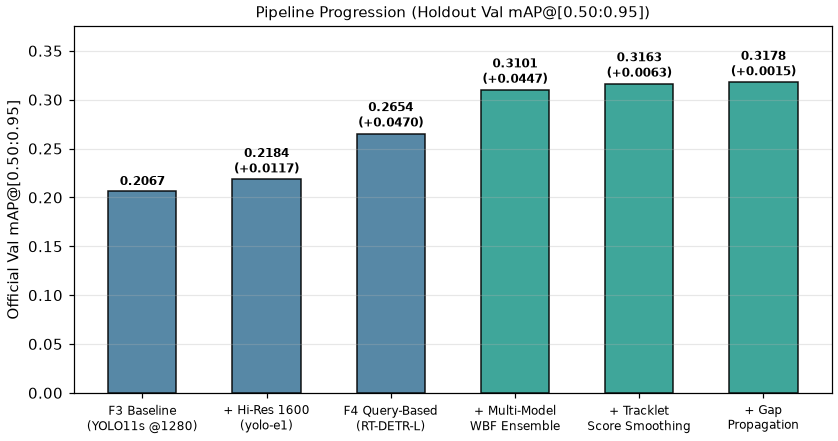

In [7]:
stages = ["yolo-e1", "yolo-e1-temporal",
          "rtdetr-e0", "ensemble-wbf", "temporal-rescore", "pipeline-final",
          "rtdetr-e3-ft", "ensemble-wbf-boost", "temporal-rescore-boost", "pipeline-night-boost",
          "ensemble-wbf-v3", "temporal-rescore-v3", "pipeline-v3"]
tbl = results_table(run_ids=stages, cols=["run_id", "AP", "AP50", "AP75", "APs", "APm", "APl", "AR500"])
display(tbl.round(4))

ap = tbl.set_index("run_id")["AP"]
print(f"Temporal on a single model (yolo-e1):       {ap['yolo-e1']:.4f} -> {ap['yolo-e1-temporal']:.4f} ({ap['yolo-e1-temporal']-ap['yolo-e1']:+.4f})")
print(f"Pipeline v1: WBF {ap['ensemble-wbf']:.4f} -> rescore {ap['temporal-rescore']:.4f} -> +propagation {ap['pipeline-final']:.4f}")
print(f"Pipeline v2: WBF {ap['ensemble-wbf-boost']:.4f} -> rescore {ap['temporal-rescore-boost']:.4f} -> +propagation/box smoothing {ap['pipeline-night-boost']:.4f}")
print(f"Pipeline v3: WBF {ap['ensemble-wbf-v3']:.4f} -> rescore {ap['temporal-rescore-v3']:.4f} -> +propagation/box smoothing {ap['pipeline-v3']:.4f}")
show_image("pipeline_waterfall.png", 850)

## 6. Online (past-only) temporal variant

Same parameters, but each frame uses only itself and earlier frames; gap filling becomes forward extrapolation.

In [8]:
from vdet.pipeline import run_temporal_variant

CAUSAL_V1 = dict(TEMPORAL, use_velocity=True, small_box_bonus=0.06, causal=True)
CAUSAL_V2 = dict(NIGHT_BOOST["temporal"], causal=True)
variants = [  # (input, input predictions, offline run, online run, temporal config)
    ("yolo-e1", P.runs / "yolo-e1" / "preds_val.parquet", "yolo-e1-temporal", "yolo-e1-temporal-causal", CAUSAL_V1),
    ("ensemble-wbf", P.runs / "pipeline-final" / "preds_val_wbf.parquet", "pipeline-final", "pipeline-final-causal", CAUSAL_V1),
    ("ensemble-wbf-boost", P.runs / "pipeline-night-boost" / "preds_val_wbf.parquet", "pipeline-night-boost", "pipeline-night-boost-causal", CAUSAL_V2),
]
rows = []
for base, inp, offline, online, cfg in variants:
    run_temporal_variant(online, inp, parent_run=base, temporal=cfg,
                         hypothesis="Online (past-only) tracklet rescoring + forward extrapolation.")
    b, off, on = run_summary(base), run_summary(offline), run_summary(online)
    rows.append({"input": base, "no temporal": b["AP"], "offline (past + future)": off["AP"], "online (past only)": on["AP"],
                 "Δ offline": off["AP"] - b["AP"], "Δ online": on["AP"] - b["AP"],
                 "APs online": on["APs"], "AR500 online": on["AR500"]})
display(pd.DataFrame(rows).set_index("input").round(4))

,no temporal,offline (past + future),online (past only),Δ offline,Δ online,APs online,AR500 online
input,,,,,,,
yolo-e1,0.2184,0.2273,0.2247,0.0089,0.0063,0.1340,0.3763
ensemble-wbf,0.2902,0.2996,0.2966,0.0095,0.0064,0.1528,0.5275
ensemble-wbf-boost,0.3046,0.3129,0.3104,0.0083,0.0058,0.1717,0.5326


**Notes.** The online variant keeps ~70% of the offline gain (+0.006 vs +0.008–0.009 AP). Submissions use the offline version.

## 7. Kaggle submissions

In [9]:
from vdet.submission import validate
rows = [{"file": p.name, **validate(p, P.test_images_csv)} for p in sorted(P.subs.glob("*.csv"))]
display(pd.DataFrame(rows))

# Public-leaderboard scores are entered by hand in experiments/lb.csv (run_id, submission_file, lb_public, date, notes)
display(pd.read_csv(P.lb_csv))

,file,valid,rows,non_empty_rows,total_detections,mean_dets_per_frame
0,ensemble_wbf.csv,True,3811,3811,1891183,496.24
1,ensemble_wbf_boost.csv,True,3811,3811,1905500,500.00
2,ensemble_wbf_v3.csv,True,3811,3811,1905500,500.00
3,frcnn-e0.csv,True,3811,3811,1683297,441.69
4,frcnn-e1.csv,True,3811,3811,1905500,500.00
5,frcnn-e2.csv,True,3811,3811,1892598,496.61
6,pipeline_final.csv,True,3811,3811,1891002,496.20
7,pipeline_night_boost.csv,True,3811,3811,1905500,500.00
8,pipeline_v3.csv,True,3811,3811,1905500,500.00
9,rtdetr-e0.csv,True,3811,3811,1143231,299.98


,run_id,submission_file,lb_public,date,notes
0,yolo-e0,yolo-e0.csv,0.204825,2026-11-04,YOLO11s baseline @1280
1,yolo-e1,yolo-e1.csv,0.241673,2026-11-04,YOLO11s @1600
2,yolo-e2,yolo-e2.csv,0.233310,2026-11-05,YOLO11s CIoU+NWD loss
3,rtdetr-e1,rtdetr-e1.csv,0.268183,2026-11-05,RT-DETR-L 600 queries
4,ensemble-wbf,ensemble_wbf.csv,0.302853,2026-11-05,6-model WBF ensemble
5,pipeline-final,pipeline_test.csv,0.318388,2026-11-05,6-model WBF + temporal; uploaded as pipeline_t...
6,pipeline-night-boost,pipeline_test_2.csv,0.337281,2026-11-06,12-input WBF + temporal (boosted pipeline); up...
7,pipeline-v3,pipeline_v3.csv,0.327041,2026-11-13,15-input WBF (v2 + 3 Faster R-CNN) + temporal;...
